<a href="https://colab.research.google.com/github/Alex-Iatrop/ISLP_projects/blob/master/assigment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

items = pd.read_csv("items/items.csv")
rated = pd.read_csv("items/items_rated.csv")

In [7]:
items

,id,text,rating,label,evidence
0,1,Leaving out the fact that they are flying in i...,NaN,NaN,NaN
1,2,I'm white so no pudding for you Mr.Trump Unive...,NaN,NaN,NaN
2,3,"... stupid people are a fact of life, just loo...",NaN,NaN,NaN
3,4,"No, not in 'other' words, in precisely the wor...",NaN,NaN,NaN
4,5,"An ""atheist""?, now it's even more stupid since...",NaN,NaN,NaN
5,6,"So much for civility, Roy's vitriol is the sam...",NaN,NaN,NaN
6,7,"Thanks Bob, but according to Ted Baker I was w...",NaN,NaN,NaN
7,8,Julian should receive the Gold Star award from...,NaN,NaN,NaN
8,9,"Where's the outrage, klastri, homer, keaukaha,...",NaN,NaN,NaN
9,10,It williams be interesting if this starts a fu...,NaN,NaN,NaN


In [8]:
rated

,id,text,rating,label,evidence
0,1,Leaving out the fact that they are flying in i...,1,civil,not needed
1,2,I'm white so no pudding for you Mr.Trump Unive...,2,civil,not needed
2,3,"... stupid people are a fact of life, just loo...",3,toxic,stupid || look at who
3,4,"No, not in 'other' words, in precisely the wor...",2,civil,not needed
4,5,"An ""atheist""?, now it's even more stupid since...",4,toxic,it's even more stupid || IMUA!!!
5,6,"So much for civility, Roy's vitriol is the sam...",2,civil,not needed
6,7,"Thanks Bob, but according to Ted Baker I was w...",3,toxic,but according to Ted Baker I was writing barra...
7,8,Julian should receive the Gold Star award from...,3,toxic,I hope he rots.
8,9,"Where's the outrage, klastri, homer, keaukaha,...",3,toxic,"Hypocrites, liars, Bigots, racist, sexists, LOL"
9,10,It williams be interesting if this starts a fu...,4,toxic,quite a few pigs at the trough!


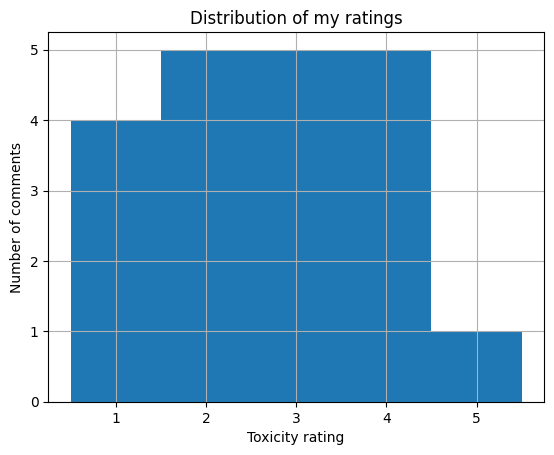

In [9]:
import matplotlib.pyplot as plt

rated["rating"].hist(bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5])
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Toxicity rating")
plt.ylabel("Number of comments")
plt.title("Distribution of my ratings")
plt.show()

For the generation of this graph I have chosen the above historgram which gathers the data of my ratings and puts them into bins of size 1. I want the centers of each rating to be at the center of the bin. Thus I have chosen the bins to start from 0.5-1.5 etc. The graph shows how I have rated the comments randomly chosen by the the items.csv. Most ratings are between 2 and 4 while I rarely selected 5. The distribution seems to be slightly right skewed, but more data is needed to draw any final conclusions.

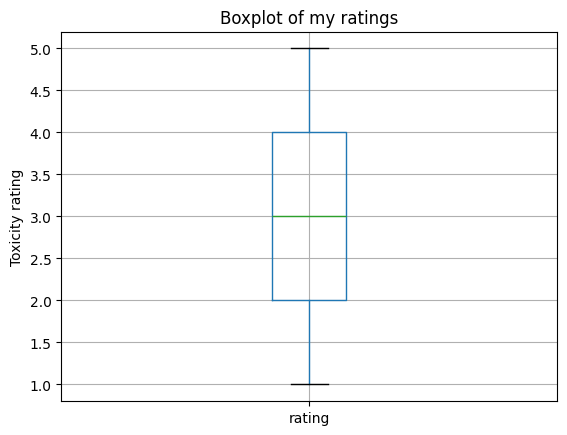

In [10]:
rated.boxplot(column="rating")
plt.ylabel("Toxicity rating")
plt.title("Boxplot of my ratings")
plt.show()

The box plot provides a summary of my ratings. We can observe that the IQR is between 2-4 ratings, that is, the 50% of the data are gathered between the two values. The slight skweness is not clearly visible here, and we cannot draw any conclusions due to the size of the sample.

In [11]:
rated["rating"].value_counts().sort_index()

,count
rating,
1,4
2,5
3,5
4,5
5,1


In [12]:
print("Number of items:", len(items))
print("Number of ratings:", len(rated))

Number of items: 20
Number of ratings: 20


In [16]:
!pip install -q syndisco

In [17]:
import json                 # to save the conversations
import random               # to choose random participants
import re                   # to find the rating in the model's answer

import pandas as pd         # for the tables
import torch                # the library that runs the model
import syndisco             # the library of this lab

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


In [18]:
texts = dict(zip(items["id"], items["text"]))

In [19]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
    name="qwen",
    max_out_tokens=80,
    generation_kwargs={"repetition_penalty": 1.1}
)

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

In [20]:
print(model)

In [21]:
# a small pool of made-up people: each is just a dictionary of attributes
PERSONAS = [
    {"username": "Maria_K", "age": 38, "job": "nurse", "personality": ["patient", "direct"]},
    {"username": "Giannis", "age": 21, "job": "game developer", "personality": ["sarcastic", "curious"]},
    {"username": "Kimya", "age": 67, "job": "retired teacher", "personality": ["strict", "grumpy"]},
    {"username": "Tom_77", "age": 45, "job": "truck driver", "personality": ["blunt", "funny"]},
    {"username": "Sofia", "age": 29, "job": "journalist", "personality": ["skeptical", "polite"]},
]

# the same context and instructions for every participant
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not refuse, "
    "do not mention that you are an AI, and never answer with an apology or a refusal."
)

In [22]:
import random

rng = random.Random(0)

# We chose the first commnet from the texts
first_id = next(iter(texts))
first_text = texts[first_id]

# we chose the first 3 participants
users = []
for persona in rng.sample(PERSONAS, 3):
    user = syndisco.Actor(
        model=model,
        persona=persona,
        context=CONTEXT,
        instructions=INSTRUCTIONS,
        name=persona["username"]
    )
    users.append(user)

discussion = syndisco.Discussion(
    next_turn_manager=syndisco.RandomTurnManager(users),
    users=users,
    conv_len=4,
    seed_opinions=[first_text],
    seed_opinion_usernames=["OriginalPoster"]
)

discussion.begin(verbose=False)

/usr/local/lib/python3.13/dist-packages/syndisco/turn_manager.py:163: UserWarning: 
                p_respond has been set to 0, which disables responding
                altogether. In that case, it may be better to use the
                RandomTurnManager class instead.
                
  warnings.warn(


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

In [23]:
for entry in discussion.get_logs():
    print(entry["name"], ":", entry["text"], "\n")

OriginalPoster : Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information. 

Sofia : It's true that their flight path through international airspace matters, but focusing solely on this detail misses other critical aspects of the situation. 

Maria_K : "Absolutely, it's crucial to consider the flight path through international airspace, but I also think we need to look at the broader impact on local communities." 

Tom_77 : "Agreed, the flight path through international airspace is important, but let's not forget about the environmental impacts and economic effects too." 

Sofia : "It’s well-rounded to acknowledge both the flight path through international airspace and its broader implications, including environmental and economic factors." 



In [25]:
context_for_item = CONTEXT + "\nOriginal comment: " + first_text

users = []
for persona in rng.sample(PERSONAS, 3):
    user = syndisco.Actor(
        model=model,
        persona=persona,
        context=context_for_item,
        instructions=INSTRUCTIONS,
        name=persona["username"]
    )
    users.append(user)

discussion = syndisco.Discussion(
    next_turn_manager=syndisco.RandomTurnManager(users),
    users=users,
    conv_len=4,
    seed_opinions=[first_text],
    seed_opinion_usernames=["OriginalPoster"]
)

discussion.begin(verbose=False)

for entry in discussion.get_logs():
    print(entry["name"], ":", entry["text"], "\n")

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

OriginalPoster : Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information. 

Giannis : It's like you're missing the big picture here. They've been flying internationally every day, right? It shouldn't be a surprise. 

Tom_77 : Flying in international airspace is just part of their routine now, but it sure makes for interesting reading when it's always left out. 

Giannis : It's true, but sometimes these details can overshadow the main story. I guess we all have our favorite bits to highlight! 

Tom_77 : Flying in international airspace might seem mundane, but it definitely adds context to their journey. It’s those little details that make stories more compelling, isn’t it? 



In [26]:
import random

rng = random.Random(0)
conversations = {}

for item_id, text in texts.items():
    # The initial comment is known to everyone
    context_for_item = CONTEXT + "\nOriginal comment: " + text

    # we chose 3 pariticipants for this disucsioon
    users = []
    for persona in rng.sample(PERSONAS, 3):
        user = syndisco.Actor(
            model=model,
            persona=persona,
            context=context_for_item,
            instructions=INSTRUCTIONS,
            name=persona["username"]
        )
        users.append(user)

    discussion = syndisco.Discussion(
        next_turn_manager=syndisco.RandomTurnManager(users),
        users=users,
        conv_len=4,
        seed_opinions=[text],
        seed_opinion_usernames=["OriginalPoster"]
    )

    discussion.begin(verbose=False)
    conversations[item_id] = discussion.get_logs()

    print(f"Conversation {item_id} completed")

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

Conversation 1 completed


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

Conversation 2 completed


... (50 outputs left out)

Conversation 19 completed


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

Conversation 20 completed


In [27]:
for item_id, logs in conversations.items():
    print(f"\n--- Conversation {item_id} ---")

    for entry in logs:
        print(f'{entry["name"]}: {entry["text"]}')


--- Conversation 1 ---
OriginalPoster: Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.
Maria_K: It's true that their flight path matters, but focusing solely on this detail misses the bigger picture. We need more context to fully understand the situation.
Tom_77: Flying in international airspace is indeed crucial info, but diving too deep into one aspect can overshadow other important details. Let's look at it all together!
Maria_K: That's a valid point. While the flight path is important, we should also consider other factors that provide a comprehensive view of the situation.
Sofia: I see your point, but I think it’s fair to highlight the key aspects without losing sight of the broader context. The flight path is certainly relevant, but so are other critical pieces of information.

--- Conversation 2 ---
OriginalPoster: I'm white so no pudding for you Mr.Trum

In [28]:
import json

with open("generated.jsonl", "w", encoding="utf-8") as f:
    for item_id, logs in conversations.items():
        entry = {
            "id": item_id,
            "conversation": [
                {"name": e["name"], "text": e["text"]}
                for e in logs
            ]
        }
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

print("Conversations saved.")

Conversations saved.


In [29]:
annotator_personas = {
    "young_left": {
        "age": "under 30",
        "politics": "left"
    },
    "young_right": {
        "age": "under 30",
        "politics": "right"
    },
    "older_left": {
        "age": "over 50",
        "politics": "left"
    },
    "older_right": {
        "age": "over 50",
        "politics": "right"
    },
    "baseline": {}
}

annotator_personas

{'young_left': {'age': 'under 30', 'politics': 'left'},
 'young_right': {'age': 'under 30', 'politics': 'right'},
 'older_left': {'age': 'over 50', 'politics': 'left'},
 'older_right': {'age': 'over 50', 'politics': 'right'},
 'baseline': {}}

In [32]:
# same intriction are given to the personas too
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is, from 1 (fully civil) "
    "to 5 (very toxic). "
    "For a rating of 3, 4 or 5, copy the exact words from the comment "
    "that justify your rating. For a rating of 1 or 2, write not needed. "
    "Reply using only this format: <number> | <evidence>."
)

# use the first comment
first_id = next(iter(texts))
first_text = texts[first_id]

# create an annotator with a persona
context = "\n".join(
    f'{entry["name"]}: {entry["text"]}'
    for entry in conversations[first_id]
)

annotator = syndisco.Actor(
    model=model,
    persona=annotator_personas["young_left"],
    context=context,
    instructions=RATING_INSTRUCTIONS,
    is_annotator=True,
    name="young_left"
)

# the log file comprises only the the comment that will be annotated
logs = syndisco.Logs()
logs.append("comment", first_text)

# execution of annotation
annotation = syndisco.Annotation(
    annotator=annotator,
    discussion_logs=logs
)

annotation.begin(verbose=False)

#  show the answer the the field of save
for entry in annotation.get_logs():
    print(entry)

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'name': 'comment', 'text': '3 | Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.', 'model': 'qwen', 'prompt': '{"context": "OriginalPoster: Leaving out the fact that they are flying in international air space, same as they were yesterday, is deceptive reporting. Why do you keep excluding that bit of information.\\nMaria_K: It\'s true that their flight path matters, but focusing solely on this detail misses the bigger picture. We need more context to fully understand the situation.\\nTom_77: Flying in international airspace is indeed crucial info, but diving too deep into one aspect can overshadow other important details. Let\'s look at it all together!\\nMaria_K: That\'s a valid point. While the flight path is important, we should also consider other factors that provide a comprehensive view of the situation.\\nSofia: I see your point, but I think it\\u2019s fai

In [33]:
import json

results = []

for persona_name, persona in annotator_personas.items():

    for condition in ["without_context", "with_context"]:

        for item_id, text in texts.items():

            # Στη δεύτερη συνθήκη ο annotator διαβάζει
            # και τη συζήτηση για το συγκεκριμένο σχόλιο.
            if condition == "with_context":
                context = "\n".join(
                    f'{entry["name"]}: {entry["text"]}'
                    for entry in conversations[item_id]
                )
            else:
                context = ""

            annotator = syndisco.Actor(
                model=model,
                persona=persona,
                context=context,
                instructions=RATING_INSTRUCTIONS,
                is_annotator=True,
                name=persona_name
            )

            logs = syndisco.Logs()
            logs.append("comment", text)

            annotation = syndisco.Annotation(
                annotator=annotator,
                discussion_logs=logs
            )

            annotation.begin(verbose=False)
            output = annotation.get_logs()[0]

            result = {
                "id": int(item_id),
                "text": text,
                "annotator": persona_name,
                "condition": condition,
                "answer": output["text"],
                "prompt": output["prompt"]
            }

            results.append(result)

            # Αποθηκεύουμε κάθε απάντηση μόλις παραχθεί
            with open("annotation_results.jsonl", "a", encoding="utf-8") as f:
                f.write(json.dumps(result, ensure_ascii=False) + "\n")

            print(f"{persona_name} | {condition} | item {item_id}: done")

print(f"Completed: {len(results)} annotations")

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


young_left | without_context | item 1: done


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


young_left | without_context | item 2: done


... (590 outputs left out)

baseline | with_context | item 19: done


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


baseline | with_context | item 20: done
Completed: 200 annotations


In [34]:
import pandas as pd

results_df = pd.DataFrame(results)

print("Total answers:", len(results_df))
display(results_df.head())

Total answers: 200


,id,text,annotator,condition,answer,prompt
0,1,Leaving out the fact that they are flying in i...,young_left,without_context,3 | Leaving out the fact that they are flying ...,"{""context"": """", ""instructions"": ""Rate how toxi..."
1,2,I'm white so no pudding for you Mr.Trump Unive...,young_left,without_context,1 | not_needed,"{""context"": """", ""instructions"": ""Rate how toxi..."
2,3,"... stupid people are a fact of life, just loo...",young_left,without_context,3 | just look at who they elected President.,"{""context"": """", ""instructions"": ""Rate how toxi..."
3,4,"No, not in 'other' words, in precisely the wor...",young_left,without_context,"3 | No, not in 'other' words, in precisely the...","{""context"": """", ""instructions"": ""Rate how toxi..."
4,5,"An ""atheist""?, now it's even more stupid since...",young_left,without_context,"3 | , now it's even more stupid since you clai...","{""context"": """", ""instructions"": ""Rate how toxi..."


In [35]:
# split the answer on the first symbol |
parts = results_df["answer"].str.split("|", n=1, expand=True)

# we create 2 new columns
results_df["rating"] = pd.to_numeric(parts[0].str.strip(), errors="coerce")
results_df["evidence"] = parts[1].str.strip() if parts.shape[1] > 1 else None

results_df[["id", "annotator", "condition", "answer", "rating", "evidence"]].head()

,id,annotator,condition,answer,rating,evidence
0,1,young_left,without_context,3 | Leaving out the fact that they are flying ...,3,Leaving out the fact that they are flying in i...
1,2,young_left,without_context,1 | not_needed,1,not_needed
2,3,young_left,without_context,3 | just look at who they elected President.,3,just look at who they elected President.
3,4,young_left,without_context,"3 | No, not in 'other' words, in precisely the...",3,"No, not in 'other' words, in precisely the wor..."
4,5,young_left,without_context,"3 | , now it's even more stupid since you clai...",3,", now it's even more stupid since you claim to..."


In [36]:
def check_answer(row):
    rating = row["rating"]
    evidence = row["evidence"]
    text = row["text"]

    if pd.isna(rating) or rating not in [1, 2, 3, 4, 5]:
        return "invalid rating"

    if rating >= 3:
        if pd.isna(evidence) or not evidence:
            return "missing evidence"

        if evidence not in text:
            return "evidence not found in text"

    return "valid"


results_df["validation"] = results_df.apply(check_answer, axis=1)

results_df["validation"].value_counts()

,count
validation,
valid,159
evidence not found in text,41


In [37]:
invalid = results_df[results_df["validation"] != "valid"]

for _, row in invalid.head(5).iterrows():
    print("ID:", row["id"])
    print("Annotator:", row["annotator"])
    print("Condition:", row["condition"])
    print("Original text:", row["text"])
    print("Model evidence:", row["evidence"])
    print("-" * 60)

ID: 7
Annotator: young_left
Condition: without_context
Original text: Thanks Bob, but according to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.
Model evidence: According to Ted Baker I was writing barracuda stories on my government work station all day and just missed the call, so feel free to go with that version if it helps.
------------------------------------------------------------
ID: 11
Annotator: young_left
Condition: without_context
Original text: So is Eric senior still eligible for “Father of the Year” if his son’s dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he’s a deviant sexual predator. Way to go Eric Sr.! Hang in there!
Model evidence: So is Eric senior still eligible for \u201cFather of the year\u201d if his son\u2019s dead body was found bloated full of

In [ ]:
def check_evidence_again(row):
    if row["validation"] != "evidence not found in text":
        return row["validation"]

    # Αφαιρούμε κενά και εξωτερικά εισαγωγικά
    cleaned = row["evidence"].strip().strip("\"'“”‘’").strip()

    if cleaned and cleaned in row["text"]:
        return "valid after removing outer quotes"

    return "evidence not found in text"


results_df["validation_review"] = results_df.apply(
    check_evidence_again, axis=1
)

results_df["validation_review"].value_counts()